In [1]:
# CreditScope - Phase 4: Build Models

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df = pd.read_csv("../Data/Credit_Cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (400, 11)


,income,credit_limit,credit_rating,num_cards,age,education_years,is_homeowner,is_student,is_married,region,balance
0,14.891,3606,283,2,34,11,0,0,1,south,333
1,106.025,6645,483,3,82,15,1,1,1,west,903
2,104.593,7075,514,4,71,11,0,0,0,west,580
3,148.924,9504,681,3,36,11,1,0,0,west,964
4,55.882,4897,357,2,68,16,0,0,1,south,331


In [2]:
# Define target and selected features

target = "balance"

selected_features = [
    "credit_limit",
    "income",
    "is_student",
    "num_cards"
]

X = df[selected_features]
y = df[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (320, 4)
Testing data: (80, 4)


In [3]:
# Build Linear Regression Model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [4]:
# Evaluate Linear Regression

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression R²:", r2_linear)

Linear Regression R²: 0.9494356957545637


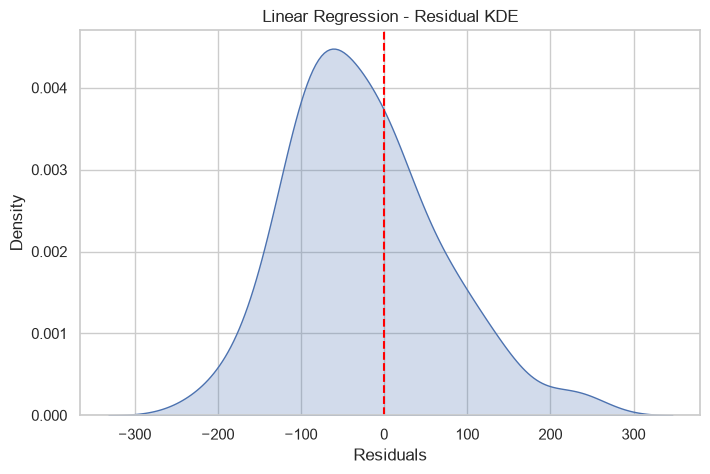

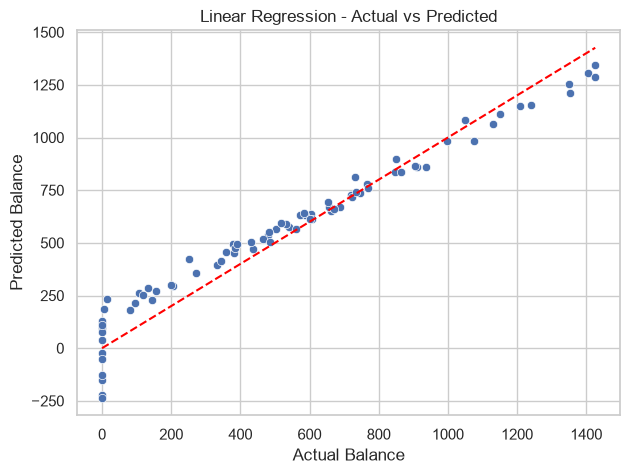

In [5]:
# Calculate residuals
residuals_linear = y_test - y_pred_linear

# 1. Residual KDE Plot
plt.figure(figsize=(8, 5))
sns.kdeplot(residuals_linear, fill=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Linear Regression - Residual KDE")
plt.xlabel("Residuals")
plt.ylabel("Density")
plt.show()

# 2. Actual vs Predicted Correlation Graph
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred_linear)

plt.xlabel("Actual Balance")
plt.ylabel("Predicted Balance")
plt.title("Linear Regression - Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)
plt.show()

In [6]:
# Build Random Forest using the same features

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [7]:
# Evaluate Random Forest

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest R²:", r2_rf)
print("Linear Regression R²:", r2_linear)

Random Forest R²: 0.9443968710960202
Linear Regression R²: 0.9494356957545637


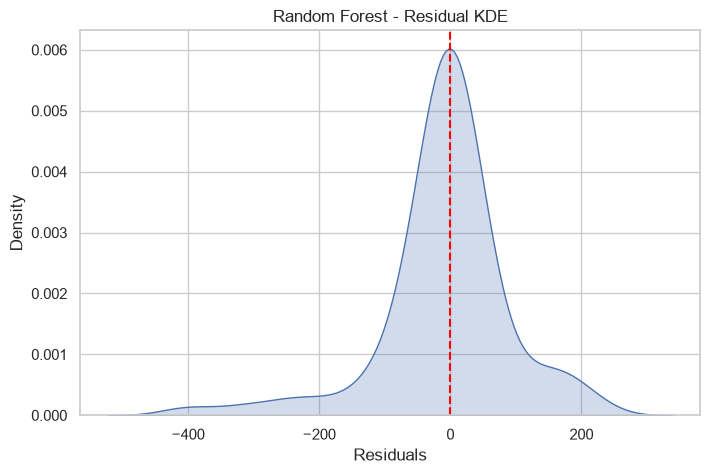

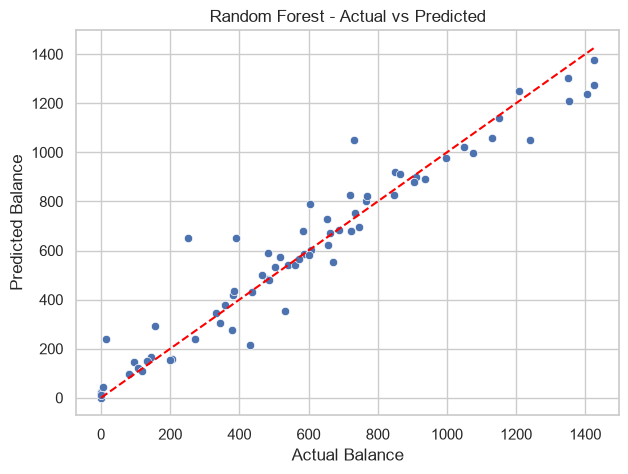

In [8]:
# Random Forest residuals
residuals_rf = y_test - y_pred_rf

# 1. Residual KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(residuals_rf, fill=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Random Forest - Residual KDE")
plt.xlabel("Residuals")
plt.ylabel("Density")
plt.show()

# 2. Actual vs Predicted
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred_rf)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Balance")
plt.ylabel("Predicted Balance")
plt.title("Random Forest - Actual vs Predicted")
plt.show()

In [9]:
# Random Forest using all features (without cluster information)

all_features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != "balance"
]

X_all = df[all_features]
y_all = df["balance"]

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=42
)

rf_all_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_all_model.fit(X_train_all, y_train_all)

y_pred_rf_all = rf_all_model.predict(X_test_all)

r2_rf_all = r2_score(y_test_all, y_pred_rf_all)

print("Features used:", all_features)
print("Random Forest (All Features) R²:", r2_rf_all)

Features used: ['income', 'credit_limit', 'credit_rating', 'num_cards', 'age', 'education_years', 'is_homeowner', 'is_student', 'is_married']
Random Forest (All Features) R²: 0.9271845074011712


In [10]:
from sklearn.preprocessing import StandardScaler
import hdbscan

# Exclude the target variable to avoid data leakage
cluster_features = df.select_dtypes(include=np.number).drop(
    columns=["balance"]
)

# Scale the features
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(cluster_features)

# Apply HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5
)

cluster_labels = clusterer.fit_predict(X_cluster_scaled)

# Add cluster labels
df["cluster"] = cluster_labels

print("Cluster distribution:")
print(df["cluster"].value_counts())

Cluster distribution:
cluster
 1    356
 0     38
-1      6
Name: count, dtype: int64


In [11]:
# Prepare all features with cluster information

X_cluster = df.drop(columns=["balance"])

# One-hot encode categorical variables and cluster labels
X_cluster = pd.get_dummies(
    X_cluster,
    columns=["region", "cluster"],
    drop_first=True,
    dtype=int
)

y_cluster = df["balance"]

# Split the data
X_train_cluster, X_test_cluster, y_train_cluster, y_test_cluster = train_test_split(
    X_cluster,
    y_cluster,
    test_size=0.2,
    random_state=42
)

# Build Random Forest
rf_cluster_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_cluster_model.fit(X_train_cluster, y_train_cluster)

# Predict
y_pred_rf_cluster = rf_cluster_model.predict(X_test_cluster)

# Evaluate
r2_rf_cluster = r2_score(y_test_cluster, y_pred_rf_cluster)

print("Random Forest with Cluster Information R²:", r2_rf_cluster)
print("Number of features:", X_cluster.shape[1])

Random Forest with Cluster Information R²: 0.9230334057528891
Number of features: 13


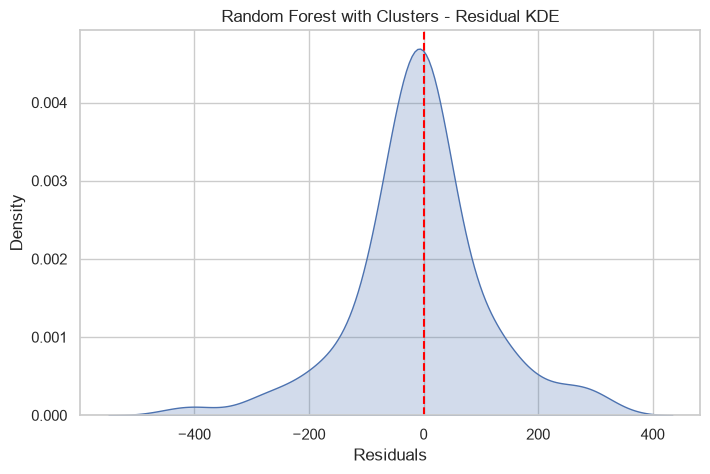

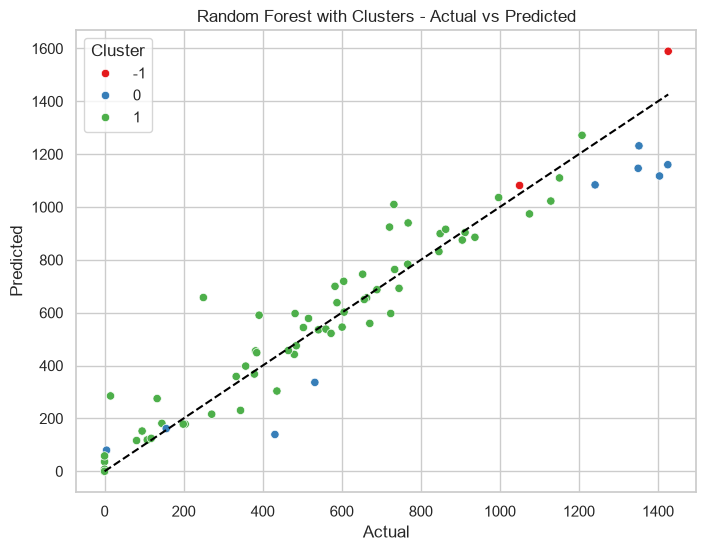

In [12]:
# Residuals for Random Forest with Clusters
residuals_cluster = y_test_cluster - y_pred_rf_cluster

# 1. Residual KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(residuals_cluster, fill=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Random Forest with Clusters - Residual KDE")
plt.xlabel("Residuals")
plt.show()

# 2. Actual vs Predicted with Cluster Hue
plot_df = pd.DataFrame({
    "Actual": y_test_cluster.values,
    "Predicted": y_pred_rf_cluster,
    "Cluster": df.loc[y_test_cluster.index, "cluster"].values
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x="Actual",
    y="Predicted",
    hue="Cluster",
    palette="Set1"
)

plt.plot(
    [plot_df["Actual"].min(), plot_df["Actual"].max()],
    [plot_df["Actual"].min(), plot_df["Actual"].max()],
    color="black",
    linestyle="--"
)

plt.title("Random Forest with Clusters - Actual vs Predicted")
plt.show()

In [13]:
# Compare Model Performance

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest (Selected Features)",
        "Random Forest (All Features)",
        "Random Forest (With Clusters)"
    ],
    "R2 Score": [
        r2_linear,
        r2_rf,
        r2_rf_all,
        r2_rf_cluster
    ]
})

display(results.sort_values(by="R2 Score", ascending=False))

,Model,R2 Score
0,Linear Regression,0.949436
1,Random Forest (Selected Features),0.944397
2,Random Forest (All Features),0.927185
3,Random Forest (With Clusters),0.923033


Model Performance Analysis

The Linear Regression model achieved the highest R² score (0.9494), slightly outperforming the Random Forest model using selected features (0.9444).

Adding all features reduced the Random Forest performance to 0.9272. Including cluster information also did not improve the model, resulting in an R² score of 0.9230.

These results suggest that the selected features are more effective than using all available features or adding cluster labels. Linear Regression provided the best predictive performance in this experiment.

In [14]:
# Simpson's Paradox Analysis

# Overall correlation
overall_corr = df["credit_limit"].corr(df["balance"])

print("Overall Correlation:")
print(overall_corr)

# Correlation within each cluster
print("\nCorrelation within each cluster:")

for cluster_id, group in df.groupby("cluster"):
    corr = group["credit_limit"].corr(group["balance"])
    print(f"Cluster {cluster_id}: {corr:.4f}")

Overall Correlation:
0.8616972670153953

Correlation within each cluster:
Cluster -1: 0.7999
Cluster 0: 0.8856
Cluster 1: 0.8887


Simpson’s Paradox Analysis

The correlation between credit limit and balance is positive in the overall dataset (0.8617) and within all three clusters.

The correlation values range from 0.7999 to 0.8887, showing that the positive relationship remains consistent across the groups.

Therefore, no clear evidence of Simpson’s Paradox was observed in this analysis, since the direction of the relationship did not reverse after grouping the data by cluster.